In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

train_set_filepath = Path("train.csv")

In [2]:
with train_set_filepath.open("r", encoding="utf-8") as f:
    records = []
    for line in f:
        elements = [e.strip() for e in line.strip().split(",") if e.strip()]
        if elements:
            records.append({'user_id': elements[0], 'navigator': elements[1], 'sequence': elements[2:]})
df = pd.DataFrame(records).set_index('user_id')

def is_timestamp(val):
    """identify the timestamps among the sequence."""
    if isinstance(val, str) and val.startswith('t') and val[1:].isdigit():
        return True
    return False

def get_seq_duration(seq):
    """Get the longest timestamp on the sequence."""
    timestamps = [int(x[1:]) for x in seq if x.startswith('t') and x[1:].isdigit()]
    return max(timestamps)

def get_macro_actions(seq):
    """
    Keep only the macro part of the action. 
    For example, "Création d'un écran(infologic.core.accueil.AccueilController)" should become ""Création d'un écran".
    """
    return [x.split('(')[0] for x in seq]


df['actions'] = df['sequence'].apply(lambda liste: [x for x in liste if not is_timestamp(x)])
df['macro_actions'] = df['actions'].apply(lambda liste: [x for x in get_macro_actions(liste)])
df['seq_duration'] = df['sequence'].apply(get_seq_duration)
df['seq_len'] = df['actions'].apply(lambda seq: len(seq))
df['actions_per_sec'] = (df['seq_len'] / df['seq_duration'].replace(0, np.nan)).fillna(0)

Nombre total d'utilisateurs uniques : 247
Nombre total de sessions : 3279


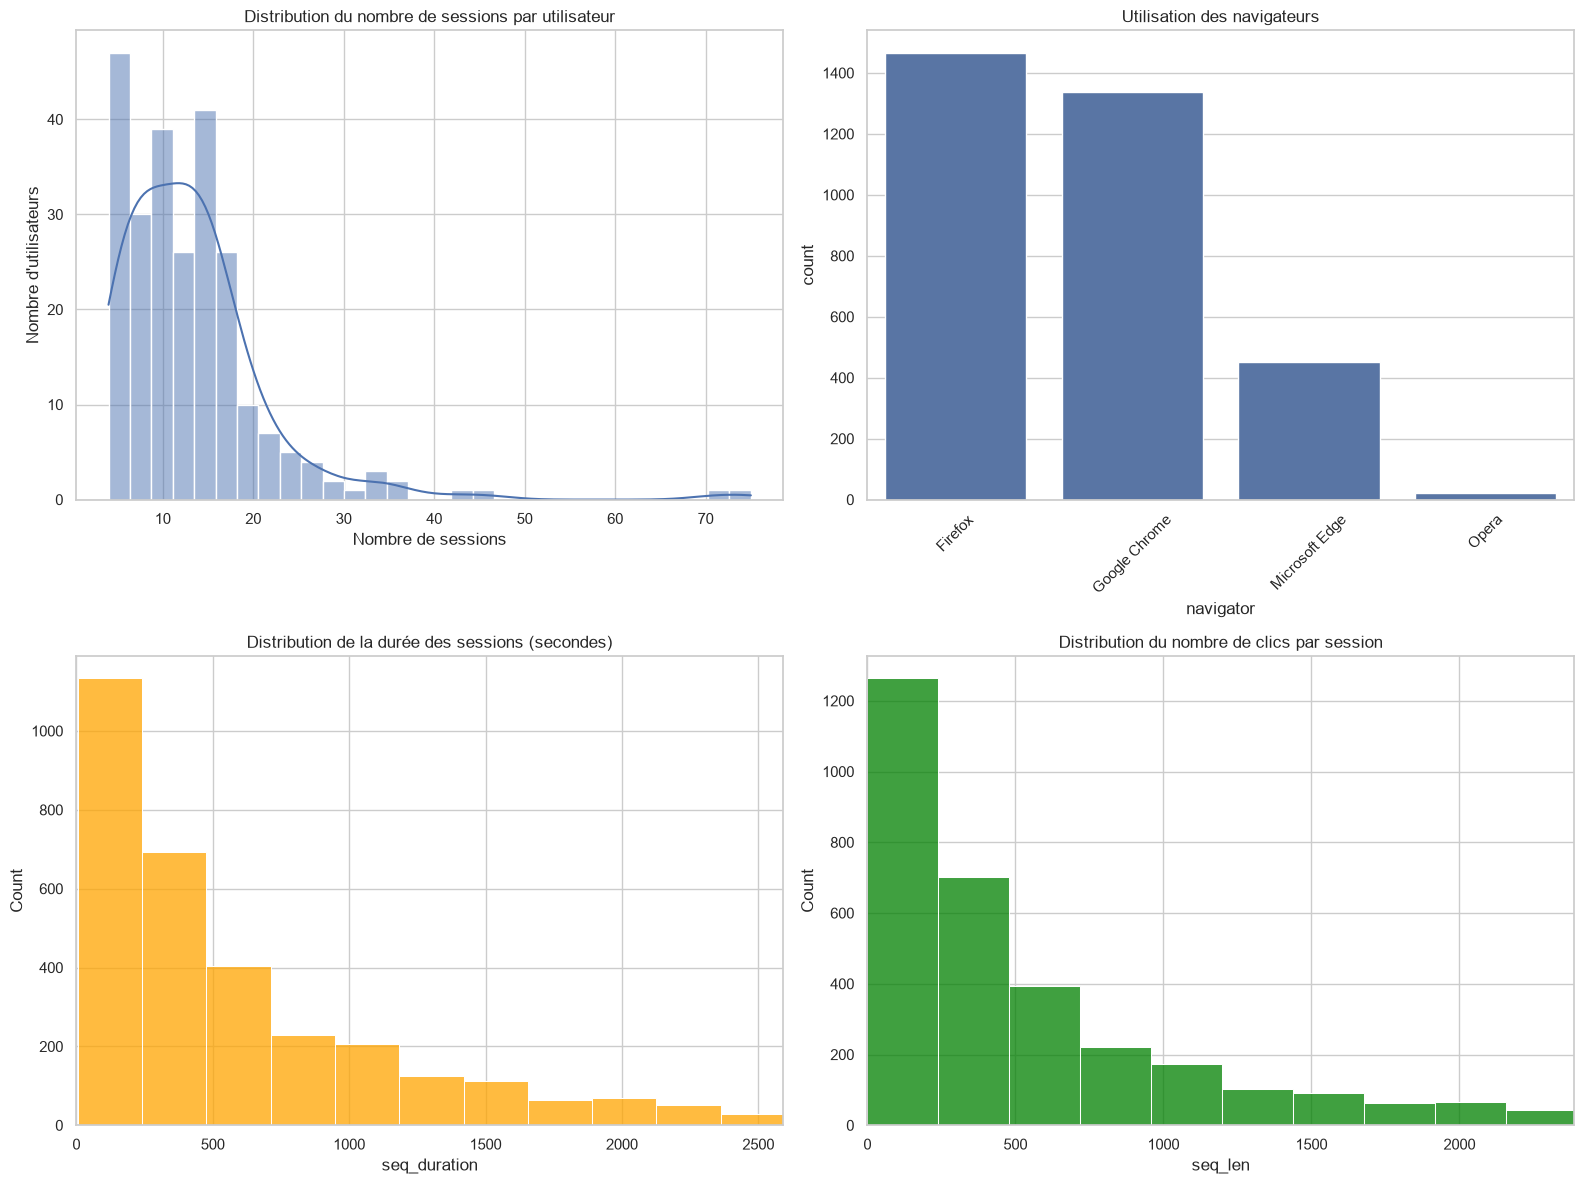

In [3]:
sns.set_theme(style="whitegrid")

# 1. Nombre de users et sessions
nb_users = df.index.nunique()
nb_sessions = len(df)
print(f"Nombre total d'utilisateurs uniques : {nb_users}")
print(f"Nombre total de sessions : {nb_sessions}")

# Préparation d'une figure avec 4 sous-graphiques (2x2)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# A. Distribution du nombre de sessions par utilisateur
sessions_par_user = df.index.value_counts()
sns.histplot(sessions_par_user, bins=30, ax=axes[0, 0], kde=True)
axes[0, 0].set_title("Distribution du nombre de sessions par utilisateur")
axes[0, 0].set_xlabel("Nombre de sessions")
axes[0, 0].set_ylabel("Nombre d'utilisateurs")

# B. Utilisation des navigateurs
sns.countplot(data=df, x='navigator', ax=axes[0, 1], order=df['navigator'].value_counts().index)
axes[0, 1].set_title("Utilisation des navigateurs")
axes[0, 1].tick_params(axis='x', rotation=45) # Pivote le texte si besoin

# C. Distribution des durées de session
sns.histplot(df['seq_duration'], bins=50, ax=axes[1, 0], color='orange')
axes[1, 0].set_title("Distribution de la durée des sessions (secondes)")
axes[1, 0].set_xlim(0, df['seq_duration'].quantile(0.95)) # Coupe les valeurs extrêmes pour la lisibilité

# D. Distribution du nombre de clics (seq_len)
sns.histplot(df['seq_len'], bins=50, ax=axes[1, 1], color='green')
axes[1, 1].set_title("Distribution du nombre de clics par session")
axes[1, 1].set_xlim(0, df['seq_len'].quantile(0.95))

plt.tight_layout()
plt.show()

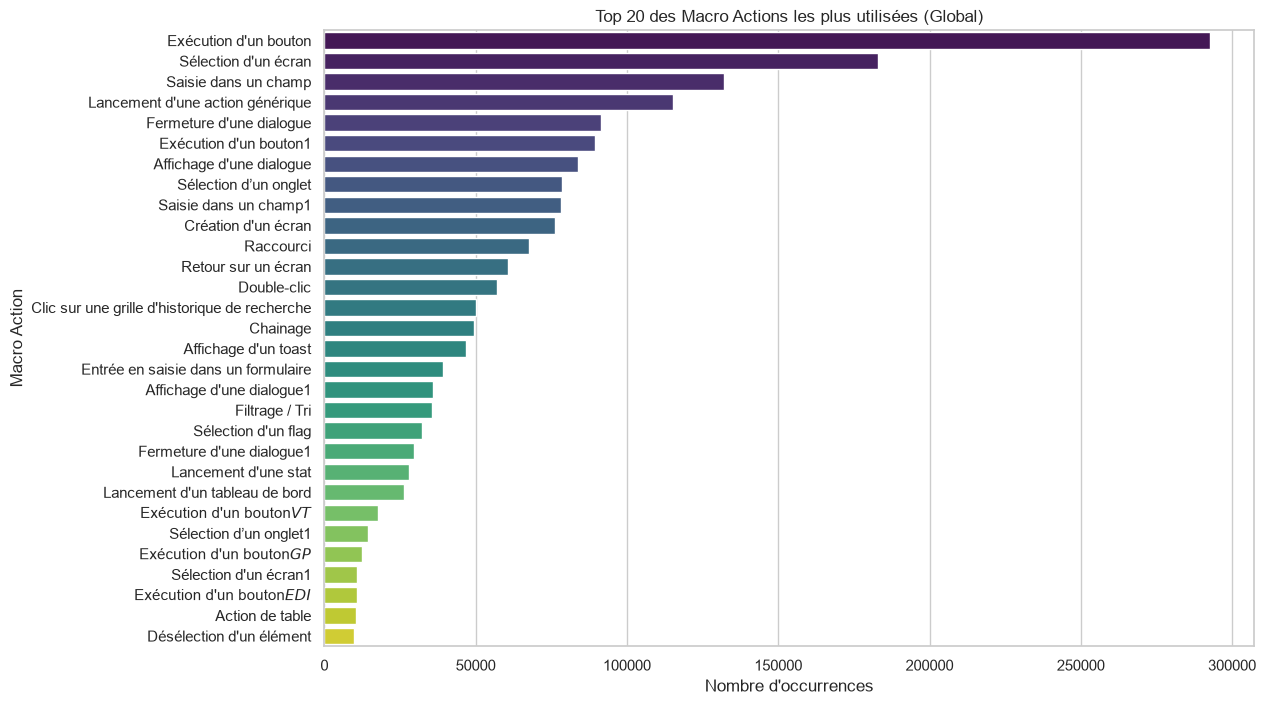

In [4]:
df_actions = df.explode("macro_actions")
top_actions_global = df_actions["macro_actions"].value_counts().head(30)

plt.figure(figsize=(12, 8))
sns.barplot(
    y=top_actions_global.index,
    x=top_actions_global.values,
    hue=top_actions_global.index,
    legend=False,
    palette="viridis",
)
plt.title("Top 20 des Macro Actions les plus utilisées (Global)")
plt.xlabel("Nombre d'occurrences")
plt.ylabel("Macro Action")
plt.show()

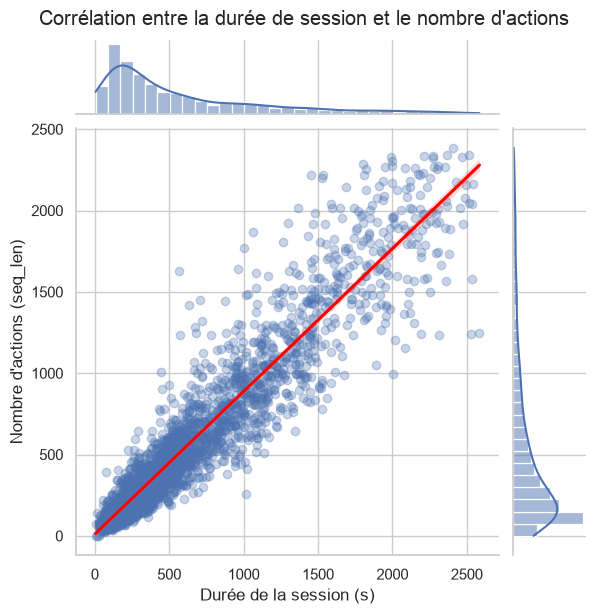

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

mask = (
    (df['seq_duration'] <= df['seq_duration'].quantile(0.95)) & 
    (df['seq_len'] <= df['seq_len'].quantile(0.95))
)
df_filtre = df[mask]

g = sns.jointplot(
    data=df_filtre, 
    x='seq_duration', 
    y='seq_len', 
    kind='reg', 
    scatter_kws={'alpha': 0.3}, 
    line_kws={'color': 'red'}
)

g.figure.suptitle("Corrélation entre la durée de session et le nombre d'actions", y=1.02)
g.set_axis_labels("Durée de la session (s)", "Nombre d'actions (seq_len)")
plt.show()

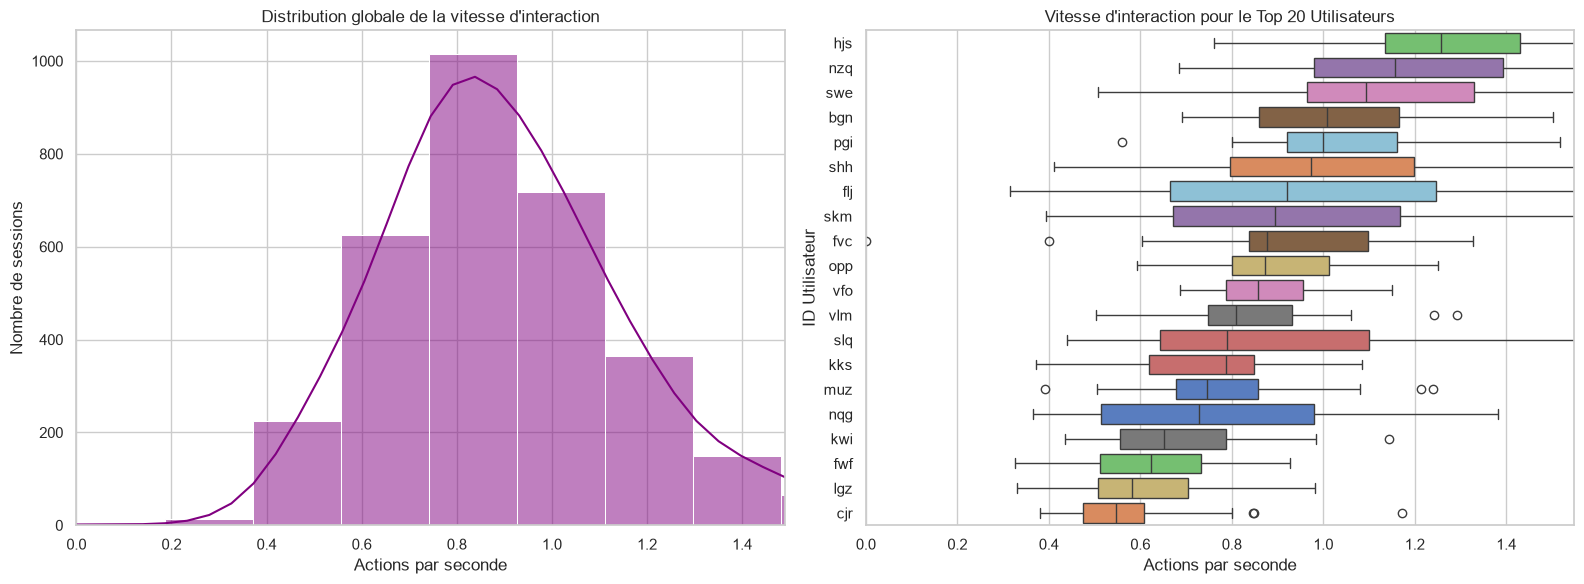

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(df['actions_per_sec'], bins=50, kde=True, ax=axes[0], color='purple')
axes[0].set_title("Distribution globale de la vitesse d'interaction")
axes[0].set_xlabel("Actions par seconde")
axes[0].set_ylabel("Nombre de sessions")
axes[0].set_xlim(0, df['actions_per_sec'].quantile(0.95))

top_20_users = df.index.value_counts().head(20).index
df_top_users = df[df.index.isin(top_20_users)]

ordre_tri = df_top_users.groupby(df_top_users.index)['actions_per_sec'].median().sort_values(ascending=False).index

sns.boxplot(
    data=df_top_users, 
    x='actions_per_sec', 
    y=df_top_users.index, 
    order=ordre_tri,
    hue=df_top_users.index,
    palette="muted",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Vitesse d'interaction pour le Top 20 Utilisateurs")
axes[1].set_xlabel("Actions par seconde")
axes[1].set_ylabel("ID Utilisateur")
axes[1].set_xlim(0, df_top_users['actions_per_sec'].quantile(0.95))

plt.tight_layout()
plt.show()

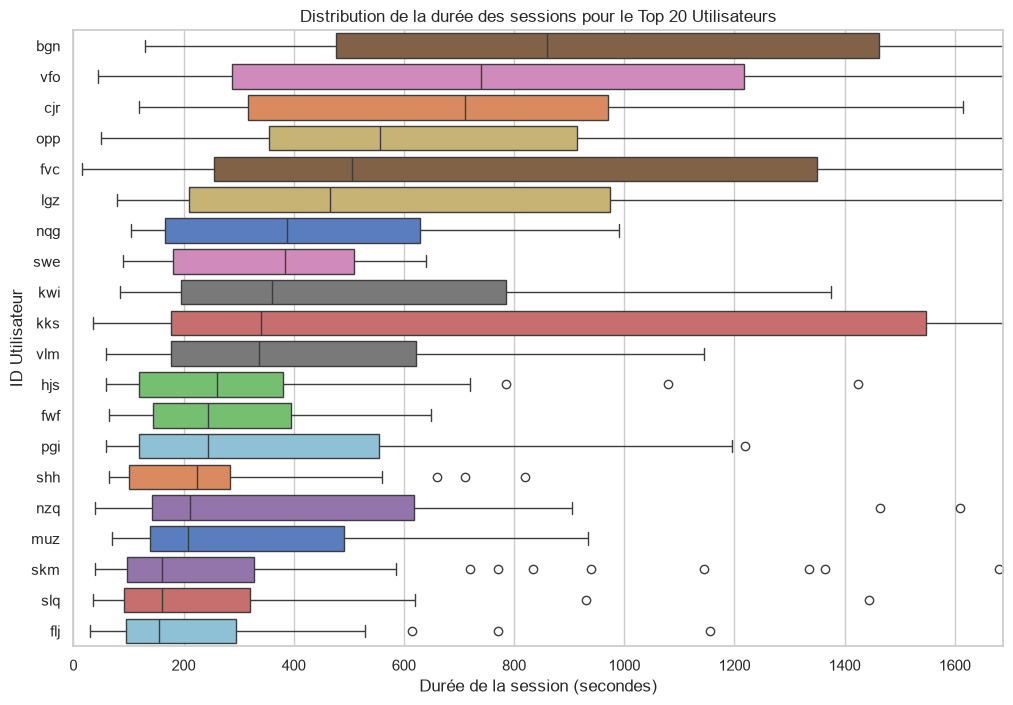

In [7]:
top_20_users = df.index.value_counts().head(20).index
df_top_users = df[df.index.isin(top_20_users)]

plt.figure(figsize=(12, 8))
ordre_tri = df_top_users.groupby(df_top_users.index)['seq_duration'].median().sort_values(ascending=False).index

sns.boxplot(
    data=df_top_users, 
    x='seq_duration', 
    y=df_top_users.index, 
    order=ordre_tri,
    hue=df_top_users.index,
    palette="muted",
    legend=False
)

plt.title("Distribution de la durée des sessions pour le Top 20 Utilisateurs")
plt.xlabel("Durée de la session (secondes)")
plt.ylabel("ID Utilisateur")

plt.xlim(0, df_top_users['seq_duration'].quantile(0.95))

plt.show()

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler
import scipy.sparse as sp
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.svm import LinearSVC

# 1. Transformation des clics en "langage"
# On remplace les espaces par des underscores pour que scikit-learn comprenne que 
# "Création_écran" est un seul mot indivisible.
df['phrase_actions'] = df['macro_actions'].apply(
    lambda liste: " ".join([act.replace(" ", "_") for act in liste])
)

# 2. La machine de guerre : Vectorisation TF-IDF avec N-grammes automatiques
# ngram_range=(1, 3) analyse l'action seule, l'action + la suivante, et la chaîne de 3 actions.
# max_features=3000 garde les 3000 combinaisons les plus informatives pour ne pas surcharger la RAM.
vectoriseur = TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 3), max_features=3000)

# X_nlp est une matrice creuse très optimisée mathématiquement
X_nlp = vectoriseur.fit_transform(df['phrase_actions'])

# 3. Préparation des autres variables (Biométrie et Contexte)
# Encodage des navigateurs
df_navigateurs = pd.get_dummies(df['navigator'], prefix='nav')

# Mise à l'échelle de tes deux variables continues
scaler = StandardScaler()
X_num = scaler.fit_transform(df[['seq_duration', 'actions_per_sec']].fillna(0))

# 4. Fusion des trois mondes : Texte + Chiffres + Navigateurs
# sp.hstack permet de coller des matrices creuses efficacement
X_final = sp.hstack([X_nlp, X_num, df_navigateurs.values])
y_final = df.index  # Ta cible reste l'ID utilisateur

X_train, X_test, y_train, y_test = train_test_split(
    X_final, y_final, test_size=0.2, random_state=42
)

# 6. Entraînement classique avec LinearSVC
modele_nlp = LinearSVC(C=1.0, class_weight='balanced', max_iter=5000, random_state=42)
modele_nlp.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forthe dual coordinate descent (if ``dual=True``). When ``dual=False`` theunderlying implementation of :class:`LinearSVC` is not random and``random_state`` has no effect on the results.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_iter max_iter: int, default=1000The maximum number of iterations to be run.",5000
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_

In [9]:
# Configuration de la validation croisée (5 plis, avec mélange aléatoire)
n_splits = 4
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

# L'exécution automatique (n_jobs=-1 permet d'utiliser tous les cœurs de ton Mac pour calculer en parallèle)
scores_f1 = cross_val_score(
    modele_nlp, 
    X_final, 
    y_final, 
    cv=skf, 
    scoring='f1_macro', 
    n_jobs=-1
)

# Affichage des résultats individuels et du score global
for pli, score in enumerate(scores_f1, 1):
    print(f"Pli {pli}/{n_splits} - F1 Score Macro : {score:.4f}")

print("-" * 40)
print(f"Score F1 Macro Final : {scores_f1.mean():.4f} (+/- {scores_f1.std():.4f})")

Pli 1/4 - F1 Score Macro : 0.9355
Pli 2/4 - F1 Score Macro : 0.9323
Pli 3/4 - F1 Score Macro : 0.9372
Pli 4/4 - F1 Score Macro : 0.9380
----------------------------------------
Score F1 Macro Final : 0.9357 (+/- 0.0022)
